# Cidadão Seguro — Dashboard de Energia dos Pontos de Ônibus
**Soluções em Energias Renováveis e Sustentáveis (SERS)** · Global Solution 2026.2

| Integrante | RM |
|---|---|
| Valeria Conceição Dos Santos | 574489 |
| Hellen Fabia Assis dos Santos | 575236 |
| Maria Eduarda Laines Braga | 576030 |

Este notebook é a contribuição de SERS ao projeto **Cidadão Seguro**. Ele calcula o consumo dos abrigos de ônibus do bairro, compara três alternativas de energia (uma renovável), simula o funcionamento durante chuvas e apagões e mostra os indicadores no dashboard.

> Todas as economias e reduções de emissão abaixo são **projeções.**

## 1. Diagnóstico

| Item | Descrição |
|---|---|
| **Espaço** | Os 10 abrigos de ônibus do bairro Vila Aurora (bairro simulado do projeto Cidadão Seguro) |
| **Problema energético** | Os abrigos usam lâmpadas fluorescentes ligadas a noite inteira e dependem só da rede elétrica. Gastam mais energia do que precisam e **ficam no escuro quando a chuva derruba a energia**, justamente quando o passageiro mais precisa |
| **Público beneficiado** | Passageiros que esperam o ônibus à noite: estudantes, trabalhadores do turno noturno, idosos e pessoas com mobilidade reduzida |
| **Condições de funcionamento** | Iluminação das 18h às 6h (12 h/noite), painel informativo de horários das 5h às 23h (18 h/dia) e tomada USB para recarga de celular |
| **Benefícios esperados** | Menor consumo e menor custo para o município, menos emissões, ponto iluminado mesmo durante apagões e dados de funcionamento enviados ao Cidadão Seguro |

**Ligação com nossa solução Cidadão Seguro:** ponto escuro e falta de energia em dia de chuva são exatamente os problemas de segurança da rua que o nosso projeto trata.

## 2. Dados e premissas

In [ ]:
# Célula 2.1 — Premissas (valor, unidade e fonte de cada dado)
PREMISSAS = {
    "tarifa_kwh":        {"valor": (259.83 + 174.33) / 1000, "unidade": "R$/kWh",
                          "fonte": "Enel SP, B4a Iluminação Pública (TUSD 259,83 + TE 174,33 R$/MWh), REH ANEEL 3.596/2026, sem impostos"},
    "fator_emissao":     {"valor": 59.9 / 1000, "unidade": "kg CO2e/kWh",
                          "fonte": "Balanço Energético Nacional 2025 (ano base 2024): 59,9 kg CO2e por MWh no setor elétrico"},
    "hsp":               {"valor": 4.0, "unidade": "h/dia",
                          "fonte": "Premissa conservadora: São Paulo recebe 4,5–4,8 kWh/m²/dia em média (CRESESB SunData); usamos 4,0 para cobrir sombra e inverno"},
    "performance_ratio": {"valor": 0.75, "unidade": "—", "fonte": "Premissa: taxa de desempenho típica de sistemas fotovoltaicos (perdas de calor, cabos e controlador)"},
    "horas_noite":       {"valor": 12, "unidade": "h/dia", "fonte": "Premissa: iluminação das 18h às 6h"},
    "horas_painel":      {"valor": 18, "unidade": "h/dia", "fonte": "Premissa: painel de horários das 5h às 23h"},
    "numero_abrigos":    {"valor": 10, "unidade": "abrigos", "fonte": "Premissa: abrigos do bairro Vila Aurora"},
}

def p(nome):
    return PREMISSAS[nome]["valor"]

for nome, d in PREMISSAS.items():
    print(f"{nome:<18} {d['valor']:<8.4g} {d['unidade']:<12} | {d['fonte']}")

tarifa_kwh         0.4342   R$/kWh       | Enel SP, B4a Iluminação Pública (TUSD 259,83 + TE 174,33 R$/MWh), REH ANEEL 3.596/2026, sem impostos
fator_emissao      0.0599   kg CO2e/kWh  | Balanço Energético Nacional 2025 (ano base 2024): 59,9 kg CO2e por MWh no setor elétrico
hsp                4        h/dia        | Premissa conservadora: São Paulo recebe 4,5–4,8 kWh/m²/dia em média (CRESESB SunData); usamos 4,0 para cobrir sombra e inverno
performance_ratio  0.75     —            | Premissa: taxa de desempenho típica de sistemas fotovoltaicos (perdas de calor, cabos e controlador)
horas_noite        12       h/dia        | Premissa: iluminação das 18h às 6h
horas_painel       18       h/dia        | Premissa: painel de horários das 5h às 23h
numero_abrigos     10       abrigos      | Premissa: abrigos do bairro Vila Aurora


### 2.2 Equipamentos de cada alternativa (mesma necessidade: iluminar, informar e recarregar)

| Alternativa | Iluminação | Painel informativo | USB | Fonte de energia |
|---|---|---|---|---|
| **A — Atual** | 2 lâmpadas fluorescentes 40 W + reator (90 W), acesas 12 h | LED 15 W, 18 h | 20 Wh/dia | Rede elétrica |
| **B — LED na rede** | 2 tubos LED 18 W (36 W) com sensor de presença: 100% com gente, 30% sem ninguém | LED 15 W, 18 h | 20 Wh/dia | Rede elétrica |
| **C — Solar com bateria** | Igual à B | LED 15 W, 18 h | 20 Wh/dia | Painel solar + bateria (sem rede) |

Premissa do sensor: em média 4 h por noite com passageiros (100%) e 8 h sem ninguém (30%), o que equivale a 6,4 h de uso pleno.

In [ ]:
# Célula 2.3 — Cargas de cada alternativa (W e horas por dia)
HORAS_EQUIV_SENSOR = 4 + 0.3 * 8    # 6,4 h de uso pleno por noite

ALTERNATIVAS = {
    "A — Atual (fluorescente na rede)": [
        {"item": "Iluminação fluorescente", "potencia_w": 90, "horas": p("horas_noite")},
        {"item": "Painel informativo",      "potencia_w": 15, "horas": p("horas_painel")},
        {"item": "Tomada USB",              "potencia_w": 10, "horas": 2},
    ],
    "B — LED com sensor na rede": [
        {"item": "Iluminação LED + sensor", "potencia_w": 36, "horas": HORAS_EQUIV_SENSOR},
        {"item": "Painel informativo",      "potencia_w": 15, "horas": p("horas_painel")},
        {"item": "Tomada USB",              "potencia_w": 10, "horas": 2},
    ],
    "C — Solar com bateria": [
        {"item": "Iluminação LED + sensor", "potencia_w": 36, "horas": HORAS_EQUIV_SENSOR},
        {"item": "Painel informativo",      "potencia_w": 15, "horas": p("horas_painel")},
        {"item": "Tomada USB",              "potencia_w": 10, "horas": 2},
    ],
}

## 3. Análise do consumo

Usamos a fórmula do enunciado, **E = (P × t) / 1000**, com P em watts e t em horas, para obter a energia em kWh.
Período de referência comum a todas as alternativas: **1 dia → 30 dias → 1 ano**, para **1 abrigo** e para os **10 abrigos**.

In [ ]:
# Célula 3.1 — Consumo por equipamento e por alternativa
import pandas as pd

def energia_kwh(potencia_w, horas):
    """E = (P × t) / 1000"""
    return potencia_w * horas / 1000

linhas = []
consumo_dia = {}
for alt, cargas in ALTERNATIVAS.items():
    total = 0
    for c in cargas:
        e = energia_kwh(c["potencia_w"], c["horas"])
        total += e
        linhas.append({"alternativa": alt, "equipamento": c["item"], "P (W)": c["potencia_w"],
                       "t (h/dia)": round(c["horas"], 1), "E (kWh/dia)": round(e, 3)})
    consumo_dia[alt] = total

pd.DataFrame(linhas)

,alternativa,equipamento,P (W),t (h/dia),E (kWh/dia)
0,A — Atual (fluorescente na rede),Iluminação fluorescente,90,12.0,1.08
1,A — Atual (fluorescente na rede),Painel informativo,15,18.0,0.27
2,A — Atual (fluorescente na rede),Tomada USB,10,2.0,0.02
3,B — LED com sensor na rede,Iluminação LED + sensor,36,6.4,0.23
4,B — LED com sensor na rede,Painel informativo,15,18.0,0.27
5,B — LED com sensor na rede,Tomada USB,10,2.0,0.02
6,C — Solar com bateria,Iluminação LED + sensor,36,6.4,0.23
7,C — Solar com bateria,Painel informativo,15,18.0,0.27
8,C — Solar com bateria,Tomada USB,10,2.0,0.02


In [ ]:
# Célula 3.2 — Resumo do consumo
N = p("numero_abrigos")
resumo = []
for alt, e_dia in consumo_dia.items():
    resumo.append({"alternativa": alt,
                   "kWh/dia (1 abrigo)": round(e_dia, 2),
                   "kWh/mês (1 abrigo)": round(e_dia * 30, 1),
                   "kWh/mês (10 abrigos)": round(e_dia * 30 * N, 1),
                   "kWh/ano (10 abrigos)": round(e_dia * 365 * N)})
pd.DataFrame(resumo)

,alternativa,kWh/dia (1 abrigo),kWh/mês (1 abrigo),kWh/mês (10 abrigos),kWh/ano (10 abrigos)
0,A — Atual (fluorescente na rede),1.37,41.1,411.0,5000
1,B — LED com sensor na rede,0.52,15.6,156.1,1899
2,C — Solar com bateria,0.52,15.6,156.1,1899


## 4. Dimensionamento da alternativa solar (C)

- **Painel:** Potência (Wp) = Energia diária ÷ (HSP × PR)
- **Bateria:** precisa cobrir **2 noites sem sol**, como em dias seguidos de chuva, que também são os dias de apagão. Usamos bateria de lítio LiFePO4 12,8 V e 150 Ah, com 80% de profundidade de descarga. Uma primeira versão, com 100 Ah, ficou no escuro na simulação de 3 dias seguidos de chuva (Seção 6), por isso aumentamos.

In [ ]:
# Célula 4.1 — Dimensionamento
ALT_C = "C — Solar com bateria"
energia_c_wh = consumo_dia[ALT_C] * 1000

potencia_minima_wp = energia_c_wh / (p("hsp") * p("performance_ratio"))
PAINEL_WP = 300                       # módulo comercial escolhido, com folga para o inverno
BATERIA_WH = 12.8 * 150               # 12,8 V × 150 Ah
BATERIA_UTIL_WH = BATERIA_WH * 0.8    # 80% de profundidade de descarga
autonomia_noites = BATERIA_UTIL_WH / energia_c_wh
geracao_media_wh = PAINEL_WP * p("hsp") * p("performance_ratio")

print(f"Consumo diário (C): {energia_c_wh:.0f} Wh")
print(f"Potência mínima do painel: {potencia_minima_wp:.0f} Wp → escolhido: {PAINEL_WP} Wp")
print(f"Geração média estimada: {geracao_media_wh:.0f} Wh/dia ({geracao_media_wh / energia_c_wh:.0%} do consumo)")
print(f"Bateria: {BATERIA_WH:.0f} Wh ({BATERIA_UTIL_WH:.0f} Wh úteis) → autonomia de {autonomia_noites:.1f} dias sem sol")

Consumo diário (C): 520 Wh
Potência mínima do painel: 173 Wp → escolhido: 300 Wp
Geração média estimada: 900 Wh/dia (173% do consumo)
Bateria: 1920 Wh (1536 Wh úteis) → autonomia de 3.0 dias sem sol


## 5. Comparação das alternativas

**Custos de implantação** (por abrigo). São estimativas do grupo com base em preços de varejo de novembro de 2026 e servem como ordem de grandeza: **não são orçamento comercial**.

| Item | B — LED na rede | C — Solar com bateria |
|---|---|---|
| Lâmpadas e sensor | 2 tubos LED (R$ 70) + sensor (R$ 60) | 2 tubos LED (R$ 70) + sensor (R$ 60) |
| Painel solar 300 Wp + suporte | — | R$ 600 |
| Controlador de carga MPPT | — | R$ 350 |
| Bateria LiFePO4 12,8 V 150 Ah | — | R$ 3.800 |
| Cabos, gabinete e proteção | — | R$ 400 |
| Mão de obra | R$ 150 | R$ 700 |
| **Total** | **R$ 280** | **R$ 5.980** |

A alternativa A já está instalada, então o custo de implantação dela é zero.

In [ ]:
# Célula 5.1 — Custos de operação, emissões e custo em 10 anos (por abrigo)
CUSTO_IMPLANTACAO = {"A — Atual (fluorescente na rede)": 0,
                     "B — LED com sensor na rede": 280,
                     "C — Solar com bateria": 5980}
MANUTENCAO_ANO = {"A — Atual (fluorescente na rede)": 60,   # troca de lâmpadas e reator a cada ~2 anos
                  "B — LED com sensor na rede": 15,         # LED dura 25 mil h ou mais
                  "C — Solar com bateria": 30}              # limpeza do painel
TROCA_BATERIA = 3800      # LiFePO4 ~3.000 ciclos ≈ 8 a 9 anos → uma troca dentro de 10 anos

def da_rede(alt):
    return alt != ALT_C

comparacao = []
for alt, e_dia in consumo_dia.items():
    kwh_rede_mes = e_dia * 30 if da_rede(alt) else 0
    custo_mes = kwh_rede_mes * p("tarifa_kwh")
    co2_ano = e_dia * 365 * p("fator_emissao") if da_rede(alt) else 0
    custo_10_anos = CUSTO_IMPLANTACAO[alt] + (custo_mes * 12 + MANUTENCAO_ANO[alt]) * 10
    if alt == ALT_C:
        custo_10_anos += TROCA_BATERIA
    comparacao.append({"alternativa": alt,
                       "kWh da rede/mês": round(kwh_rede_mes, 1),
                       "conta R$/mês": round(custo_mes, 2),
                       "implantação R$": CUSTO_IMPLANTACAO[alt],
                       "CO2e kg/ano": round(co2_ano, 1),
                       "% renovável": 100 if alt == ALT_C else 0,
                       "custo total 10 anos R$": round(custo_10_anos)})

tabela_comparacao = pd.DataFrame(comparacao)
tabela_comparacao

,alternativa,kWh da rede/mês,conta R$/mês,implantação R$,CO2e kg/ano,% renovável,custo total 10 anos R$
0,A — Atual (fluorescente na rede),41.1,17.84,0,30.0,0,2741
1,B — LED com sensor na rede,15.6,6.78,280,11.4,0,1243
2,C — Solar com bateria,0.0,0.00,5980,0.0,100,10080


### 5.2 Viabilidade, impactos, benefícios e limitações

| | A — Atual | B — LED na rede | C — Solar com bateria |
|---|---|---|---|
| **Viabilidade técnica** | Já instalada | Simples: troca de lâmpadas e um sensor | Precisa de sol no teto do abrigo (sem sombra de prédios ou árvores) e de proteção contra furto da bateria |
| **Impacto ambiental** | Maior consumo; lâmpada fluorescente tem mercúrio | Consumo cerca de 62% menor; LED dura muito mais | Zero energia da rede; a bateria precisa de descarte correto no fim da vida útil |
| **Benefícios** | — | Menor custo total em 10 anos e retorno rápido | **Funciona durante apagões** e não precisa de ligação à rede (bom para abrigos novos ou isolados) |
| **Limitações** | Apaga junto com a rede | Apaga junto com a rede | Custo inicial alto; em dias seguidos sem sol, o sistema prioriza a iluminação e desliga o painel e a USB |

**Conclusão da comparação:** se a decisão for só pela conta de luz, a **B** vence. A **C** é a única que garante luz durante apagões, mas custa bem mais. Por isso propomos uma **solução híbrida**: LED com sensor em todos os abrigos e **kit solar nos 3 pontos críticos** escolhidos pelo grupo (em frente à escola, em frente à UBS e na área que alaga).

In [ ]:
# Célula 5.3 — Cenário híbrido proposto (10 abrigos: 7 do tipo B + 3 do tipo C)
ALT_A, ALT_B = "A — Atual (fluorescente na rede)", "B — LED com sensor na rede"
QTD_B, QTD_C = 7, 3

def linha(alt):
    return tabela_comparacao[tabela_comparacao["alternativa"] == alt].iloc[0]

atual = {"kwh_mes": consumo_dia[ALT_A] * 30 * N, "custo_mes": linha(ALT_A)["conta R$/mês"] * N,
         "co2_ano": linha(ALT_A)["CO2e kg/ano"] * N}
hibrido = {"kwh_mes": consumo_dia[ALT_B] * 30 * QTD_B,
           "custo_mes": linha(ALT_B)["conta R$/mês"] * QTD_B,
           "co2_ano": linha(ALT_B)["CO2e kg/ano"] * QTD_B,
           "implantacao": CUSTO_IMPLANTACAO[ALT_B] * QTD_B + CUSTO_IMPLANTACAO[ALT_C] * QTD_C}

consumo_total_hibrido = (consumo_dia[ALT_B] * QTD_B + consumo_dia[ALT_C] * QTD_C) * 30
print(f"Consumo da rede: {atual['kwh_mes']:.0f} → {hibrido['kwh_mes']:.0f} kWh/mês (10 abrigos)")
print(f"Conta de energia: R$ {atual['custo_mes']:.2f} → R$ {hibrido['custo_mes']:.2f} por mês")
print(f"Investimento inicial: R$ {hibrido['implantacao']:,.0f}".replace(",", "."))
print(f"Abrigos que continuam acesos num apagão: 0 → {QTD_C}")

Consumo da rede: 411 → 109 kWh/mês (10 abrigos)
Conta de energia: R$ 178.40 → R$ 47.46 por mês
Investimento inicial: R$ 19.900
Abrigos que continuam acesos num apagão: 0 → 3


## 6. Simulação de monitoramento (30 dias)

Para o dashboard mostrar como o sistema se comporta, simulamos 30 dias com **dados simulados**: sol variando de um dia para o outro, alguns dias de chuva forte (pouco sol) e **dois apagões na rede** nos dias de temporal.

A lógica de automação é a do diagrama: se ao anoitecer a bateria estiver abaixo de 50%, o abrigo solar desliga o painel e a USB e **mantém só a iluminação**.

In [ ]:
# Célula 6.1 — Simulação de 30 dias (dados simulados, semente fixa para repetir o resultado)
import random
random.seed(2026)

DIAS_CHUVA = [8, 9, 19, 20, 21]
DIAS_APAGAO = [9, 20]                 # temporal derruba a rede

carga = BATERIA_UTIL_WH               # começa com a bateria cheia
consumo_luz_wh = 36 * HORAS_EQUIV_SENSOR
simulacao = []
for dia in range(1, 31):
    sol = random.uniform(0.6, 1.4) * p("hsp")
    if dia in DIAS_CHUVA:
        sol = random.uniform(0.3, 0.8)
    geracao = PAINEL_WP * sol * p("performance_ratio")
    carga = min(BATERIA_UTIL_WH, carga + geracao)

    carga_anoitecer = carga
    # lógica de automação: com menos de 50% de carga ao anoitecer, só a iluminação fica ligada
    if carga / BATERIA_UTIL_WH < 0.50:
        demanda = consumo_luz_wh
        modo = "economia"
    else:
        demanda = energia_c_wh
        modo = "normal"
    solar_aceso = carga >= consumo_luz_wh
    carga = max(0, carga - demanda)

    simulacao.append({"dia": dia, "sol (h)": round(sol, 1), "geração (Wh)": round(geracao),
                      "bateria ao anoitecer (%)": round(100 * carga_anoitecer / BATERIA_UTIL_WH),
                      "bateria ao amanhecer (%)": round(100 * carga / BATERIA_UTIL_WH), "modo": modo,
                      "apagão na rede": dia in DIAS_APAGAO,
                      "abrigo na rede aceso": dia not in DIAS_APAGAO,
                      "abrigo solar aceso": solar_aceso})

sim = pd.DataFrame(simulacao)
noites_solar = int(sim["abrigo solar aceso"].sum())
noites_rede = int(sim["abrigo na rede aceso"].sum())
print(f"Noites iluminadas em 30 dias — abrigo na rede: {noites_rede} | abrigo solar: {noites_solar}")
sim[sim["dia"].isin(DIAS_CHUVA)]

Noites iluminadas em 30 dias — abrigo na rede: 28 | abrigo solar: 30


,dia,sol (h),geração (Wh),bateria ao anoitecer (%),bateria ao amanhecer (%),modo,apagão na rede,abrigo na rede aceso,abrigo solar aceso
7,8,0.7,156,76,42,normal,False,True,True
8,9,0.7,150,52,18,normal,True,False,True
18,19,0.6,144,75,42,normal,False,True,True
19,20,0.4,96,48,33,economia,True,False,True
20,21,0.8,172,44,29,economia,False,True,True


## 7. Indicadores

| # | Indicador | Unidade | De onde vem |
|---|---|---|---|
| 1 | Consumo de energia da rede (10 abrigos) | kWh/mês | Seções 3 e 5.3 |
| 2 | Economia energética | % | Comparação atual × híbrido |
| 3 | Redução de custo | R$/mês | Tarifa B4a × kWh economizados |
| 4 | Emissões evitadas | kg CO2e/ano | kWh economizados × fator de emissão |
| 5 | Participação de energia renovável | % | Abrigos solares ÷ consumo total |
| 6 | Noites iluminadas durante apagões | noites | Simulação da Seção 6 |

In [ ]:
# Célula 7.1 — Cálculo dos indicadores (cenário híbrido × situação atual)
INDICADORES = {
    "Consumo da rede (10 abrigos)": (round(hibrido["kwh_mes"], 1), "kWh/mês"),
    "Economia energética": (round(100 * (1 - hibrido["kwh_mes"] / atual["kwh_mes"])), "%"),
    "Redução de custo": (round(atual["custo_mes"] - hibrido["custo_mes"], 2), "R$/mês"),
    "Emissões evitadas": (round(atual["co2_ano"] - hibrido["co2_ano"], 1), "kg CO2e/ano"),
    "Energia renovável": (round(100 * consumo_dia[ALT_C] * QTD_C * 30 / consumo_total_hibrido), "%"),
    "Noites acesas em apagões (abrigos solares)": (sum(1 for d in simulacao if d["apagão na rede"] and d["abrigo solar aceso"]), f"de {len(DIAS_APAGAO)}"),
}
for nome, (valor, unidade) in INDICADORES.items():
    print(f"{nome:<44} {valor} {unidade}")

Consumo da rede (10 abrigos)                 109.3 kWh/mês
Economia energética                          73 %
Redução de custo                             130.94 R$/mês
Emissões evitadas                            220.2 kg CO2e/ano
Energia renovável                            30 %
Noites acesas em apagões (abrigos solares)   2 de 2


## 8. Dashboard

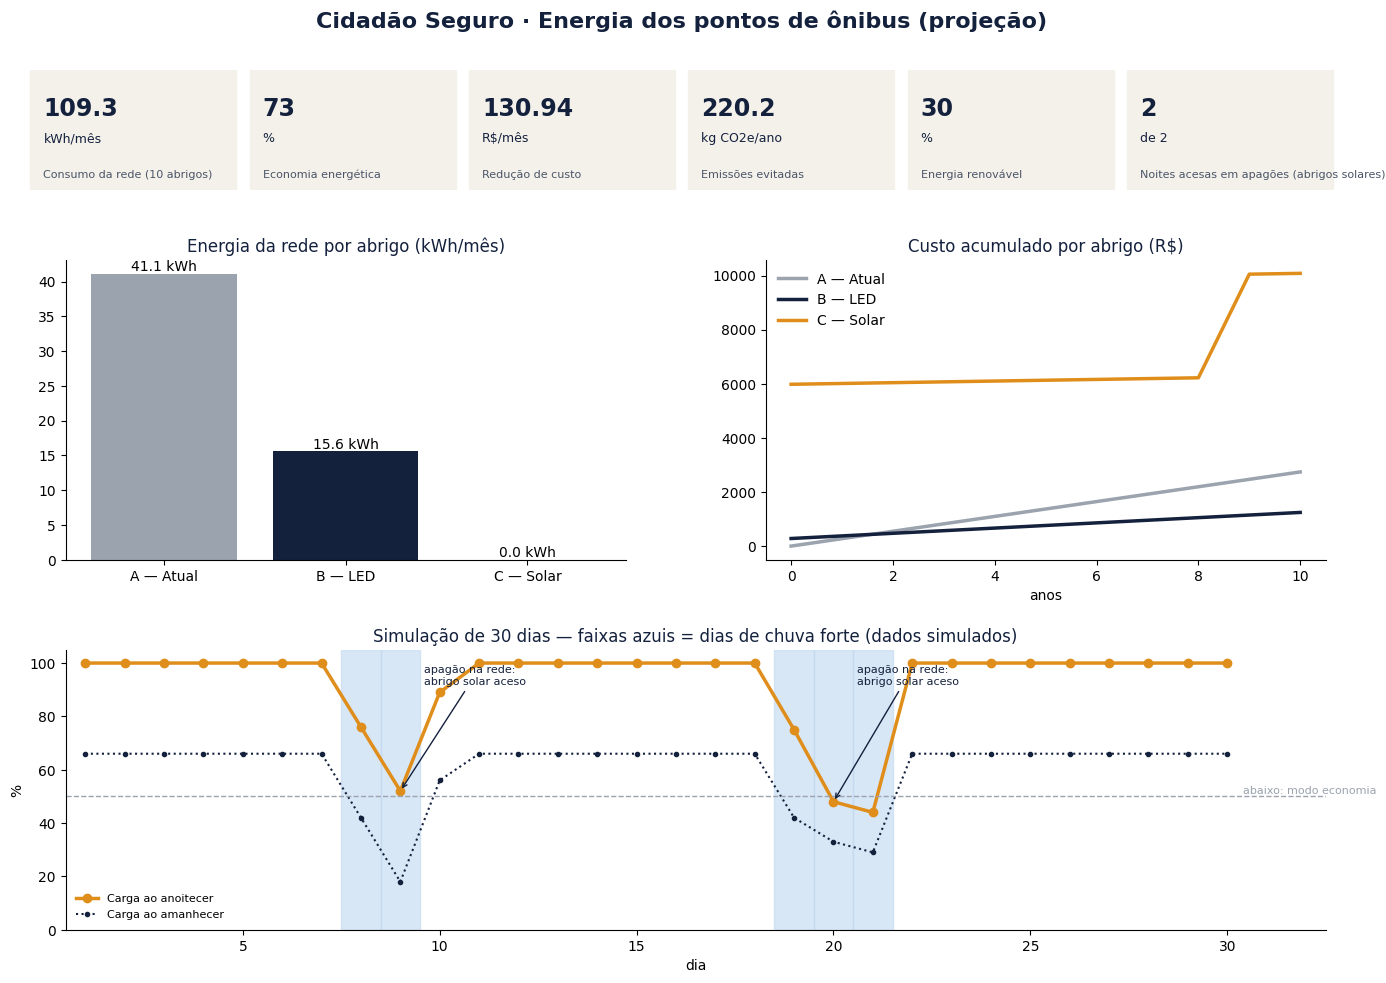

In [ ]:
# Célula 8.1 — Painel de indicadores e gráficos
import matplotlib.pyplot as plt

AZUL, AMBAR, CINZA = "#14213D", "#E08E1B", "#9AA3AE"
cores = [CINZA, AZUL, AMBAR]
nomes_curtos = ["A — Atual", "B — LED", "C — Solar"]

fig = plt.figure(figsize=(14, 10))
fig.suptitle("Cidadão Seguro · Energia dos pontos de ônibus (projeção)", fontsize=16, fontweight="bold", color=AZUL)

# cartões de indicadores
ax0 = fig.add_axes([0.03, 0.80, 0.94, 0.12]); ax0.axis("off")
cartoes = list(INDICADORES.items())
for i, (nome, (valor, unidade)) in enumerate(cartoes):
    x = i / len(cartoes) + 0.005
    ax0.add_patch(plt.Rectangle((x, 0), 1 / len(cartoes) - 0.01, 1, color="#F4F1EA", transform=ax0.transAxes))
    ax0.text(x + 0.01, 0.62, f"{valor}", fontsize=17, fontweight="bold", color=AZUL, transform=ax0.transAxes)
    ax0.text(x + 0.01, 0.40, unidade, fontsize=9, color=AZUL, transform=ax0.transAxes)
    ax0.text(x + 0.01, 0.10, nome, fontsize=8, color="#4A5568", transform=ax0.transAxes, wrap=True)

# gráfico 1: consumo da rede por abrigo
ax1 = fig.add_axes([0.06, 0.43, 0.40, 0.30])
valores = [r["kWh da rede/mês"] for r in comparacao]
barras = ax1.bar(nomes_curtos, valores, color=cores)
ax1.bar_label(barras, fmt="%.1f kWh")
ax1.set_title("Energia da rede por abrigo (kWh/mês)", color=AZUL)
ax1.spines[["top", "right"]].set_visible(False)

# gráfico 2: custo acumulado em 10 anos
ax2 = fig.add_axes([0.56, 0.43, 0.40, 0.30])
anos = list(range(0, 11))
for r, cor, nome in zip(comparacao, cores, nomes_curtos):
    acumulado = []
    for ano in anos:
        valor = r["implantação R$"] + (r["conta R$/mês"] * 12 + MANUTENCAO_ANO[r["alternativa"]]) * ano
        if r["alternativa"] == ALT_C and ano >= 9:
            valor += TROCA_BATERIA
        acumulado.append(valor)
    ax2.plot(anos, acumulado, color=cor, linewidth=2.5, label=nome)
ax2.set_title("Custo acumulado por abrigo (R$)", color=AZUL)
ax2.set_xlabel("anos"); ax2.legend(frameon=False)
ax2.spines[["top", "right"]].set_visible(False)

# gráfico 3: bateria do abrigo solar na simulação de 30 dias
ax3 = fig.add_axes([0.06, 0.06, 0.90, 0.28])
ax3.plot(sim["dia"], sim["bateria ao anoitecer (%)"], color=AMBAR, linewidth=2.5, marker="o", label="Carga ao anoitecer")
ax3.plot(sim["dia"], sim["bateria ao amanhecer (%)"], color=AZUL, linewidth=1.5, linestyle=":", marker=".", label="Carga ao amanhecer")
ax3.legend(frameon=False, loc="lower left", fontsize=8)
for d in DIAS_CHUVA:
    ax3.axvspan(d - 0.5, d + 0.5, color="#BFD8F0", alpha=0.6)
for d in DIAS_APAGAO:
    ax3.annotate("apagão na rede:\nabrigo solar aceso", xy=(d, sim.loc[d - 1, "bateria ao anoitecer (%)"]),
                 xytext=(d + 0.6, 92), fontsize=8, color=AZUL, arrowprops=dict(arrowstyle="->", color=AZUL))
ax3.axhline(50, color=CINZA, linestyle="--", linewidth=1)
ax3.text(30.4, 51, "abaixo: modo economia", fontsize=8, color=CINZA)
ax3.set_ylim(0, 105); ax3.set_xlim(0.5, 32.5)
ax3.set_title("Simulação de 30 dias — faixas azuis = dias de chuva forte (dados simulados)", color=AZUL)
ax3.set_xlabel("dia"); ax3.set_ylabel("%")
ax3.spines[["top", "right"]].set_visible(False)

plt.savefig("dashboard_energia.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Limitações

- Os custos de implantação são **estimativas de ordem de grandeza**, não orçamento comercial.
- A tarifa usada é a B4a da Enel SP **sem impostos**; com impostos, a economia em reais seria maior.
- As horas de sol são uma média conservadora; sombras de prédios ou árvores reduzem a geração.
- A simulação de 30 dias usa **dados simulados**, não medições reais.
- As emissões consideram só a operação; a fabricação do painel e da bateria não entra na conta.
- Como a matriz elétrica brasileira já é bastante renovável, o ganho ambiental vem mais da **eficiência (LED)** do que da troca de fonte.